<a href="https://colab.research.google.com/github/jonitodev/PembelajaranMesin/blob/main/JS07/JS07_Assigment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS07 — Tugas Lab

## Import library dan load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


## 1. Scatterplot

Nama kolom jumlah kartu pada CSV adalah `Total_Credit_Cards`.

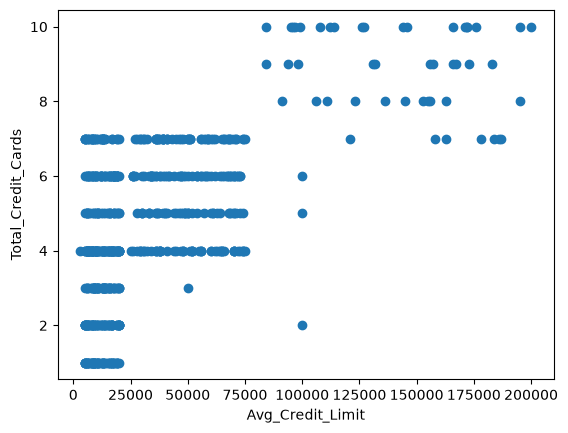

In [ ]:
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'])
plt.show()

Ada kecenderungan positif, tetapi titik menyebar dalam beberapa kelompok dan tidak mengikuti satu garis lurus.

## 2. K-Means dan elbow method

Gunakan dua fitur pada soal 1. Standardisasi diperlukan agar nilai limit kredit tidak mendominasi jumlah kartu.

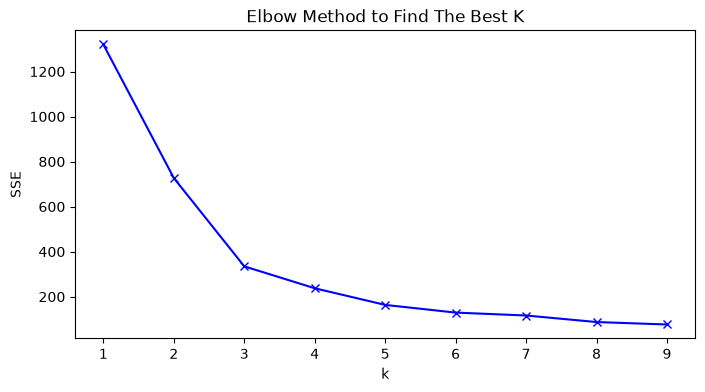

In [ ]:
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sse = []
K = range(1, 10)
for k in K:
    kmeanModel = KMeans(n_clusters=k)
    kmeanModel.fit(X_scaled)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method to Find The Best K')
plt.show()

Dipilih **k = 3** karena SSE turun tajam hingga sekitar k = 3, kemudian penurunannya lebih kecil.

## 3. Scatterplot hasil K-Means

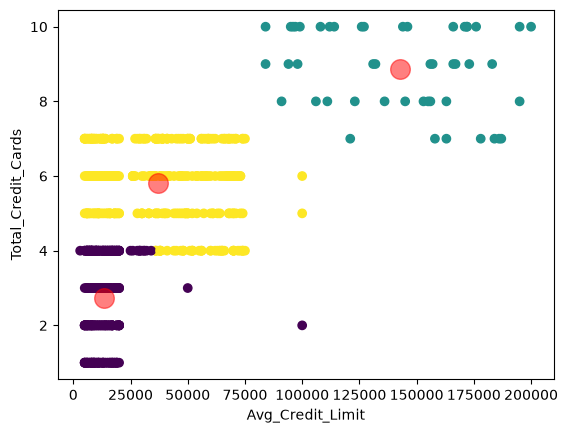

In [ ]:
cl_kmeans = KMeans(n_clusters=3)
y_kmeans = cl_kmeans.fit_predict(X_scaled)
centers = scaler.inverse_transform(cl_kmeans.cluster_centers_)

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_kmeans)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.show()

## 4. DBSCAN dengan seluruh fitur yang dapat digunakan

Kolom `Sl_No` dan `Customer Key` dikeluarkan karena merupakan pengenal. Lima fitur lainnya distandarisasi; pemilihan parameter dijelaskan pada nomor 5.

In [ ]:
X_db = df.iloc[:, 2:]
X_db_scaled = StandardScaler().fit_transform(X_db)

dbscan = DBSCAN(eps=1.4, min_samples=10)
cluster_db = dbscan.fit_predict(X_db_scaled)

## 5. Pemilihan parameter DBSCAN

DBSCAN tidak memakai jumlah klaster `k`. Grafik jarak tetangga digunakan untuk memilih `eps`, dengan `min_samples = 10`; urutan tetangga mencakup titik sendiri.

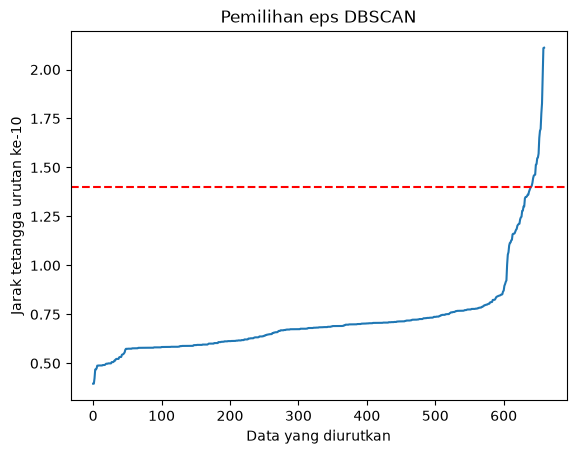

In [ ]:
neighbors = NearestNeighbors(n_neighbors=10)
neighbors.fit(X_db_scaled)
distances, indices = neighbors.kneighbors(X_db_scaled)
distances = np.sort(distances[:, -1])

plt.plot(distances)
plt.axhline(1.4, color='red', linestyle='--')
plt.xlabel('Data yang diurutkan')
plt.ylabel('Jarak tetangga urutan ke-10')
plt.title('Pemilihan eps DBSCAN')
plt.show()

In [ ]:
hasil = []
for eps in [0.8, 1.0, 1.2, 1.4, 1.5]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X_db_scaled)
    jumlah_cluster = len(set(labels) - {-1})
    jumlah_noise = np.sum(labels == -1)
    hasil.append([eps, jumlah_cluster, jumlah_noise])

pd.DataFrame(hasil, columns=['eps', 'Jumlah klaster', 'Jumlah noise'])

,eps,Jumlah klaster,Jumlah noise
0,0.8,1,54
1,1.0,1,53
2,1.2,2,13
3,1.4,2,3
4,1.5,2,3


Siku awal sekitar **0,8** hanya menghasilkan satu klaster. Dipilih **eps = 1,4** karena hasil stabil pada 1,4–1,5: dua klaster dan tiga noise; ini pilihan eksploratif berdasarkan kurva dan tabel.

## 6. Silhouette score dan DBI

Noise (`-1`) dikeluarkan dari evaluasi. Kedua metrik memerlukan minimal dua klaster.

In [ ]:
mask = cluster_db != -1
X_eval = X_db_scaled[mask]
labels_eval = cluster_db[mask]

if 2 <= len(np.unique(labels_eval)) < len(labels_eval):
    print('Silhouette score:', silhouette_score(X_eval, labels_eval))
    print('Davies-Bouldin Index:', davies_bouldin_score(X_eval, labels_eval))
else:
    print('Silhouette dan DBI tidak terdefinisi untuk hasil ini.')

print('Jumlah klaster:', len(set(cluster_db) - {-1}))
print('Jumlah noise:', np.sum(cluster_db == -1))

Silhouette score: 0.5747777459808416
Davies-Bouldin Index: 0.6242306972235019
Jumlah klaster: 2
Jumlah noise: 3


Hasil: silhouette sekitar **0,5748**, DBI **0,6242**, dengan **2 klaster** dan **3 noise**. Metrik dihitung pada 657 baris non-noise.